# Milestone 2 — L1 Sweep Experiment + Baseline Comparison

Reproduction of Cunningham et al. (ICLR 2024), *"Sparse Autoencoders Find Highly Interpretable Features in Language Models"*.

**This notebook lives on the `experiment/l1-sweep` branch. `main` holds our Milestone 1 work, unchanged.**

It uses the **same setup as Milestone 1** so the two milestones form one continuous project:

| Setting | Milestone 1 (`main`) | This notebook |
|---|---|---|
| Model | Pythia-70M, frozen | same |
| Activations | residual stream, layer 3 | same |
| Data | WikiText-103 paragraphs (> 20 chars) | same source; **20,000** paragraphs instead of 5,000 (the first 5,000 are exactly Milestone 1's) |
| Dictionary size | 2048 (R = 4) | same |
| SAE | tied weights, MSE + L1 | same equations |

**What this notebook adds:**
1. **Additional experiment (from our proposal):** L1 coefficient sweep over 9 log-spaced values on the *full* activation set (Milestone 1's sweep used only 500 vectors), with a sparsity-vs-reconstruction trade-off plot.
2. **Reproduction check:** the paper's main claim is that SAE features are more interpretable than the model's own basis directions ("neurons") and PCA directions. We test this with a **blinded** human rating of random features from each method.
3. **Deployment files:** final checkpoint + per-feature example contexts for the Streamlit app.

**Runtime:** Colab → Runtime → Change runtime type → T4 GPU → Run all. About 20–30 minutes.

In [1]:
!pip install -q transformers==4.36.2 datasets==2.16.1 accelerate==0.25.0
import os, json, math, random, time, glob
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# ---------------- configuration (all settings live here) ----------------
MODEL_NAME   = "EleutherAI/pythia-70m"
LAYER        = 3        # hidden_states[3] = residual stream after the 3rd of 6 layers (same as Milestone 1)
N_DOCS       = 20_000   # WikiText paragraphs; first 5,000 = Milestone 1's set
MAX_LENGTH   = 128      # same as Milestone 1
EVAL_FRAC    = 0.10     # last 10% of paragraphs are held out for evaluation only
R            = 4        # dictionary size = R * d_model = 2048 (fixed for the whole sweep)
ALPHAS       = [1e-3, 3e-3, 1e-2, 2e-2, 5e-2, 1e-1, 2e-1, 5e-1, 1.0]   # log-spaced, denser in the middle
EPOCHS       = 5        # passes over the training activations per SAE
BATCH_SIZE   = 2048
LR           = 1e-3
SEED         = 0
N_RATE       = 15       # random features per method in the blinded rating
OUT_DIR      = "sae_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(SEED)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.8/126.8 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 57.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 507.1/507.1 kB 22.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.7/265.7 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.3/115.3 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.4/166.4 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 71.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.4/135.4 kB 7.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2023.10.0 which is incompatible.
diffusers 

## 1. Load the frozen language model and the data

In [2]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device).eval()
for p in model.parameters():
    p.requires_grad = False
D_MODEL = model.config.hidden_size
DICT_SIZE = R * D_MODEL
print(f"d_model={D_MODEL}, dict_size={DICT_SIZE}, layers={model.config.num_hidden_layers}")

dataset = load_dataset("wikitext", "wikitext-103-raw-v1", split="train", streaming=True)
texts = []
for ex in dataset:                       # same filter and order as Milestone 1
    if len(ex["text"].strip()) > 20:
        texts.append(ex["text"])
    if len(texts) >= N_DOCS:
        break
n_train_docs = int(len(texts) * (1 - EVAL_FRAC))
print(f"{len(texts)} paragraphs: {n_train_docs} train / {len(texts) - n_train_docs} eval")

/usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/396 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


config.json:   0%|          | 0.00/567 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


model.safetensors:   0%|          | 0.00/166M [00:00<?, ?B/s]

d_model=512, dict_size=2048, layers=6


20000 paragraphs: 18000 train / 2000 eval


## 2. Cache residual-stream activations

- Every paragraph is tokenized once and its token IDs are kept, so we can later show **which text** made a feature fire.
- **Position 0 is dropped.** The first token of every sequence has an unusually large activation (it acts as an "attention sink"), so it would distort training.
- **Line-end newline tokens are dropped.** Every WikiText paragraph and heading ends with a newline token. In our first run we found these tokens have activations ~17x larger than a typical token, so ~1–2% of tokens held about two-thirds of all variance. An SAE could "explain" most of the variance by learning only the newlines, which made the reconstruction numbers misleading. We exclude them (and record how much they held, below). The app skips them too.
- These two exclusions are the only preprocessing changes from Milestone 1.
- Activations are stored in half precision on the GPU if they fit, otherwise in CPU RAM.

In [3]:
doc_tokens = [tokenizer(t, truncation=True, max_length=MAX_LENGTH)["input_ids"] for t in texts]

# tokens that are only whitespace containing a newline (WikiText line endings)
vocab_seen = {i for ids in doc_tokens for i in ids}
NEWLINE_IDS = sorted(i for i in vocab_seen if "\n" in tokenizer.decode([i]) and tokenizer.decode([i]).strip() == "")
NEWLINE_SET = set(NEWLINE_IDS)
print("newline token ids:", NEWLINE_IDS)

def kept_positions(ids):
    """Positions we train/evaluate on: not position 0, not a newline token."""
    return [p for p in range(1, len(ids)) if ids[p] not in NEWLINE_SET]

rows_per_doc = [len(kept_positions(ids)) for ids in doc_tokens]
n_rows = sum(rows_per_doc)
n_train_rows = sum(rows_per_doc[:n_train_docs])
gb = n_rows * D_MODEL * 2 / 1e9
print(f"{n_rows:,} activation vectors ({gb:.2f} GB in fp16); {n_train_rows:,} train")

store_device = device if (device == "cuda" and gb < 0.6 * torch.cuda.get_device_properties(0).total_memory / 1e9) else "cpu"
acts    = torch.empty((n_rows, D_MODEL), dtype=torch.float16, device=store_device)
row_doc = torch.empty(n_rows, dtype=torch.int32)
row_pos = torch.empty(n_rows, dtype=torch.int16)

def pad_batch(id_lists, with_labels=False):
    L = max(len(x) for x in id_lists)
    ids  = torch.full((len(id_lists), L), tokenizer.pad_token_id, dtype=torch.long)
    mask = torch.zeros((len(id_lists), L), dtype=torch.long)
    labels = torch.full((len(id_lists), L), -100, dtype=torch.long)
    for i, x in enumerate(id_lists):
        ids[i, :len(x)] = torch.tensor(x); mask[i, :len(x)] = 1; labels[i, :len(x)] = torch.tensor(x)
    return (ids, mask, labels) if with_labels else (ids, mask)

ptr, BS = 0, 32
excl = dict(n_kept=0, sq_kept=0.0, n_newline=0, sq_newline=0.0)      # raw squared norms, for the report
t0 = time.time()
with torch.no_grad():
    for start in range(0, len(doc_tokens), BS):
        batch_ids = doc_tokens[start:start + BS]
        ids, mask = pad_batch(batch_ids)
        hidden = model(input_ids=ids.to(device), attention_mask=mask.to(device), output_hidden_states=True).hidden_states[LAYER]
        for j, x in enumerate(batch_ids):
            keep = kept_positions(x)
            nl = [p for p in range(1, len(x)) if x[p] in NEWLINE_SET]
            if nl:
                excl["n_newline"] += len(nl); excl["sq_newline"] += (hidden[j, nl].float() ** 2).sum().item()
            n = len(keep)
            if n == 0: continue
            h = hidden[j, keep]
            excl["n_kept"] += n; excl["sq_kept"] += (h.float() ** 2).sum().item()
            acts[ptr:ptr + n] = h.to(store_device, torch.float16)
            row_doc[ptr:ptr + n] = start + j
            row_pos[ptr:ptr + n] = torch.tensor(keep, dtype=torch.int16)
            ptr += n
assert ptr == n_rows
print(f"cached in {time.time() - t0:.0f}s on {store_device}")

tot_n, tot_sq = excl["n_kept"] + excl["n_newline"], excl["sq_kept"] + excl["sq_newline"]
print(f"\nNEWLINE FINDING (for the report): newline tokens were {100*excl['n_newline']/tot_n:.2f}% of tokens "
      f"but held {100*excl['sq_newline']/tot_sq:.1f}% of the total squared activation (excluding position 0).")
print(f"average squared norm: newline {excl['sq_newline']/max(excl['n_newline'],1):.1f} vs other tokens {excl['sq_kept']/excl['n_kept']:.1f}")
json.dump(excl, open(f"{OUT_DIR}/newline_stats.json", "w"))

newline token ids: [187, 2490]
1,612,186 activation vectors (1.65 GB in fp16); 1,446,246 train
cached in 73s on cuda

NEWLINE FINDING (for the report): newline tokens were 0.73% of tokens but held 40.2% of the total squared activation (excluding position 0).
average squared norm: newline 22312.2 vs other tokens 243.3


## 3. Normalize activations

We subtract the training-set mean and divide by one number so the average squared length of a vector is 1. This makes the reconstruction error read directly as **fraction of variance unexplained** (FVU: 0 = perfect, 1 = no better than guessing the average). Because of this, our α values are **not on the same scale** as Milestone 1's α = 1.0, which was applied to raw, un-normalized activations. The same `MEAN` and `SCALE` are saved with the checkpoint so the app applies the identical transform.

In [4]:
@torch.no_grad()
def compute_norm_stats(chunk=200_000):
    s = torch.zeros(D_MODEL, dtype=torch.float64, device=store_device)
    for i in range(0, n_train_rows, chunk):
        s += acts[i:i + chunk].double().sum(0)
    mean = (s / n_train_rows).float()
    sq = 0.0
    for i in range(0, n_train_rows, chunk):
        sq += ((acts[i:i + chunk].float() - mean) ** 2).sum().item()
    return mean, math.sqrt(sq / n_train_rows)

MEAN, SCALE = compute_norm_stats()
MEAN_DEV = MEAN.to(device)
def get_batch(idx):
    return (acts[idx].to(device).float() - MEAN_DEV) / SCALE
print("scale:", round(SCALE, 3))

scale: 14.192


## 4. Sparse autoencoder (paper Section 2 and Appendix B)

```
c  = ReLU(M x + b)          encoder
x̂  = Mᵀ c                    decoder (tied weights, rows of M kept at unit length)
L  = ||x − x̂||² + α ||c||₁
```

In [5]:
class SparseAutoencoder(nn.Module):
    def __init__(self, d_model, dict_size):
        super().__init__()
        self.W = nn.Parameter(F.normalize(torch.randn(dict_size, d_model), dim=1))
        self.b_enc = nn.Parameter(torch.zeros(dict_size))
    def encode(self, x):
        return F.relu(x @ self.W.T + self.b_enc)
    def decode(self, c):
        return c @ self.W
    def forward(self, x):
        c = self.encode(x)
        return self.decode(c), c

def sae_loss(x, x_hat, c, alpha):
    recon = ((x - x_hat) ** 2).sum(-1).mean()
    l1 = c.abs().sum(-1).mean()
    return recon + alpha * l1, recon, l1

def train_sae(alpha, epochs=EPOCHS, log=True):
    set_seed(SEED)                                   # same start for every alpha -> fair comparison
    sae = SparseAutoencoder(D_MODEL, DICT_SIZE).to(device)
    opt = torch.optim.Adam(sae.parameters(), lr=LR)
    history = []
    for ep in range(epochs):
        perm = torch.randperm(n_train_rows, device=store_device)
        tot = rec = l1s = 0.0; nb = 0
        for i in range(0, n_train_rows, BATCH_SIZE):
            x = get_batch(perm[i:i + BATCH_SIZE])
            x_hat, c = sae(x)
            loss, r, l = sae_loss(x, x_hat, c, alpha)
            opt.zero_grad(); loss.backward(); opt.step()
            with torch.no_grad():
                sae.W.data = F.normalize(sae.W.data, dim=1)
            tot += loss.item(); rec += r.item(); l1s += l.item(); nb += 1
        history.append(dict(alpha=alpha, epoch=ep, loss=tot / nb, recon=rec / nb, l1=l1s / nb))   # per-batch MEAN
        if log:
            print(f"  alpha={alpha:g} epoch {ep} | loss {tot/nb:.4f} | recon {rec/nb:.4f} | L1 {l1s/nb:.3f}")
    return sae, history

## 5. Evaluation (held-out paragraphs only)

For each SAE we measure:
- **FVU** — fraction of variance unexplained (reconstruction error). Lower is better.
- **L0** — average number of features active per token. Lower is sparser.
- **Dead features** — features that never fire on the evaluation set.
- **Loss recovered** — we put the SAE's reconstruction back into Pythia at layer 3 (on the same tokens it was trained on; position 0 and newlines keep their real values) and check how much of the model's next-token ability survives. 100% = as good as the real activations, 0% = as bad as replacing them with the average vector. This shows whether a low FVU keeps what the model actually needs.

In [6]:
EVAL_ROWS = torch.arange(n_train_rows, n_rows)[:300_000]

@torch.no_grad()
def eval_sae(sae, chunk=8192):
    se = l0 = 0.0
    fired = torch.zeros(DICT_SIZE, dtype=torch.bool, device=device)
    for i in range(0, len(EVAL_ROWS), chunk):
        x = get_batch(EVAL_ROWS[i:i + chunk].to(store_device))
        x_hat, c = sae(x)
        se += ((x - x_hat) ** 2).sum().item()
        l0 += (c > 0).sum().item()
        fired |= (c > 0).any(0)
    n = len(EVAL_ROWS)
    var = ((get_batch(EVAL_ROWS[:50_000].to(store_device))) ** 2).sum(-1).mean().item()   # eval-set variance
    return dict(fvu=se / n / var, l0=l0 / n, dead_frac=1 - fired.float().mean().item())

def model_blocks(m):
    return m.gpt_neox.layers if hasattr(m, "gpt_neox") else m.transformer.h

EVAL_DOC_IDS = [d for d in range(n_train_docs, len(doc_tokens)) if len(doc_tokens[d]) > 1][:400]

@torch.no_grad()
def lm_loss(replace_fn=None):
    """Mean next-token loss on eval paragraphs; replace_fn edits the layer-LAYER residual at kept positions only."""
    handle, state = None, {}
    if replace_fn is not None:
        def hook(mod, inp, out):
            h = out[0] if isinstance(out, tuple) else out
            h = h.clone(); k = state["keep"]
            h[k] = replace_fn(h[k])
            return (h,) + tuple(out[1:]) if isinstance(out, tuple) else h
        handle = model_blocks(model)[LAYER - 1].register_forward_hook(hook)
    tot = cnt = 0.0
    try:
        for s in range(0, len(EVAL_DOC_IDS), 16):
            batch = [doc_tokens[d] for d in EVAL_DOC_IDS[s:s + 16]]
            ids, mask, labels = pad_batch(batch, with_labels=True)
            keep = torch.zeros_like(mask, dtype=torch.bool)
            for i, x in enumerate(batch):
                keep[i, kept_positions(x)] = True
            state["keep"] = keep.to(device)
            out = model(input_ids=ids.to(device), attention_mask=mask.to(device), labels=labels.to(device))
            n = (labels[:, 1:] != -100).sum().item()
            tot += out.loss.item() * n; cnt += n
    finally:
        if handle: handle.remove()
    return tot / cnt

CE_CLEAN = lm_loss()
CE_MEAN_ABLATE = lm_loss(lambda h: MEAN_DEV.expand_as(h).to(h.dtype))
print(f"LM loss clean {CE_CLEAN:.3f} | layer {LAYER} replaced by its mean {CE_MEAN_ABLATE:.3f}")

def loss_recovered(sae):
    def splice(h):
        x = (h.float() - MEAN_DEV) / SCALE
        return (sae(x)[0] * SCALE + MEAN_DEV).to(h.dtype)
    ce = lm_loss(splice)
    return ce, (CE_MEAN_ABLATE - ce) / (CE_MEAN_ABLATE - CE_CLEAN)

LM loss clean 4.596 | layer 3 replaced by its mean 8.762


## 6. Additional experiment: L1 coefficient sweep

Same activations, same dictionary size, same seed, same number of epochs. **Only α changes.** Every trained SAE is saved so nothing needs retraining later.

In [7]:
results, all_history, saes = [], [], {}
for a in ALPHAS:
    print(f"\n=== alpha = {a:g} ===")
    t0 = time.time()
    sae, hist = train_sae(a)
    m = eval_sae(sae)
    ce, rec = loss_recovered(sae)
    m.update(alpha=a, lm_loss=ce, loss_recovered=rec, minutes=(time.time() - t0) / 60)
    print(f"  FVU {m['fvu']:.3f} | L0 {m['l0']:.1f} | dead {100*m['dead_frac']:.1f}% | loss recovered {100*rec:.1f}%")
    results.append(m); all_history += hist
    saes[a] = {k: v.detach().cpu() for k, v in sae.state_dict().items()}
    torch.save(saes[a], f"{OUT_DIR}/sae_alpha{a:g}.pt")

df = pd.DataFrame(results)[["alpha", "fvu", "l0", "dead_frac", "lm_loss", "loss_recovered", "minutes"]]
df.to_csv(f"{OUT_DIR}/sweep_results.csv", index=False)
pd.DataFrame(all_history).to_csv(f"{OUT_DIR}/sweep_training_history.csv", index=False)
df


=== alpha = 0.001 ===
  alpha=0.001 epoch 0 | loss 0.1108 | recon 0.1007 | L1 10.077
  alpha=0.001 epoch 1 | loss 0.0363 | recon 0.0179 | L1 18.438
  alpha=0.001 epoch 2 | loss 0.0246 | recon 0.0051 | L1 19.468
  alpha=0.001 epoch 3 | loss 0.0226 | recon 0.0045 | L1 18.131
  alpha=0.001 epoch 4 | loss 0.0213 | recon 0.0041 | L1 17.160
  FVU 0.005 | L0 491.4 | dead 0.0% | loss recovered 99.8%

=== alpha = 0.003 ===
  alpha=0.003 epoch 0 | loss 0.1311 | recon 0.1043 | L1 8.947
  alpha=0.003 epoch 1 | loss 0.0674 | recon 0.0384 | L1 9.686
  alpha=0.003 epoch 2 | loss 0.0431 | recon 0.0115 | L1 10.533
  alpha=0.003 epoch 3 | loss 0.0377 | recon 0.0076 | L1 10.028
  alpha=0.003 epoch 4 | loss 0.0353 | recon 0.0065 | L1 9.625
  FVU 0.007 | L0 439.5 | dead 0.0% | loss recovered 99.6%

=== alpha = 0.01 ===
  alpha=0.01 epoch 0 | loss 0.1854 | recon 0.1144 | L1 7.099
  alpha=0.01 epoch 1 | loss 0.1216 | recon 0.0635 | L1 5.812
  alpha=0.01 epoch 2 | loss 0.0986 | recon 0.0404 | L1 5.817
  alph

,alpha,fvu,l0,dead_frac,lm_loss,loss_recovered,minutes
0,0.001,0.004713,491.411751,0.000000,4.606782,0.997526,0.490011
1,0.003,0.006972,439.455074,0.000000,4.611997,0.996274,0.481123
2,0.010,0.024625,316.056460,0.000000,4.674821,0.981194,0.476930
3,0.020,0.059081,162.267512,0.000000,4.830246,0.943886,0.476386
4,0.050,0.123500,54.727468,0.000000,5.140551,0.869401,0.476515
5,0.100,0.194137,24.850753,0.000000,5.599456,0.759246,0.476459
6,0.200,0.495801,1.058340,0.000000,8.607951,0.037092,0.462943
7,0.500,0.530183,0.109359,0.001465,8.766466,-0.000958,0.459226
8,1.000,0.532942,0.093805,0.006348,8.767731,-0.001261,0.459444


In [8]:
# Sanity check on the alpha range: the sweep should span dense -> very sparse.
if df["l0"].min() > 20:
    print("WARNING: even the largest alpha is not very sparse. Add larger alphas to ALPHAS and rerun section 6.")
if df["l0"].max() < 100:
    print("WARNING: even the smallest alpha is already sparse. Add smaller alphas to ALPHAS and rerun section 6.")

## 7. Trade-off plot (main result of the additional experiment)

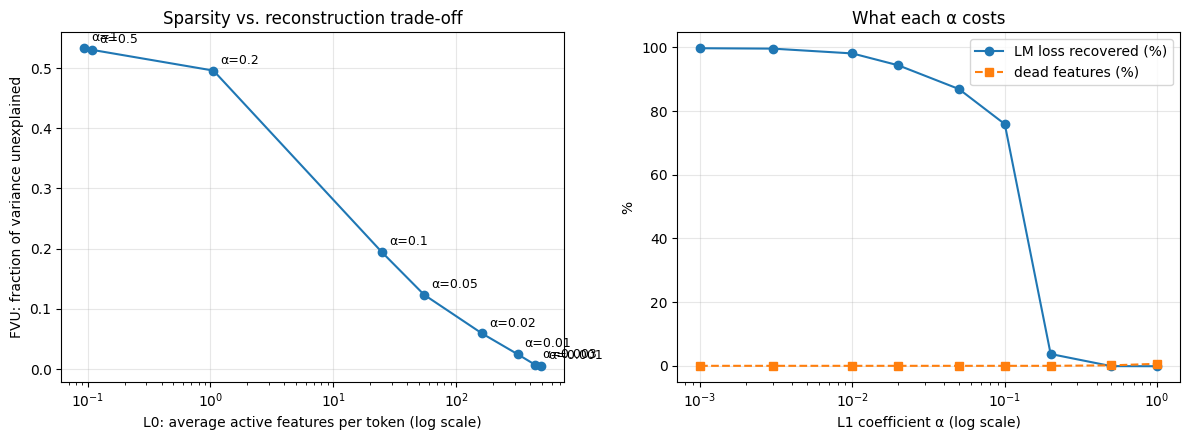

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(df["l0"], df["fvu"], "o-")
for _, r in df.iterrows():
    ax[0].annotate(f"α={r['alpha']:g}", (r["l0"], r["fvu"]), textcoords="offset points", xytext=(5, 5), fontsize=9)
ax[0].set_xscale("log"); ax[0].set_xlabel("L0: average active features per token (log scale)")
ax[0].set_ylabel("FVU: fraction of variance unexplained"); ax[0].set_title("Sparsity vs. reconstruction trade-off")
ax[0].grid(alpha=.3)

ax[1].plot(df["alpha"], 100 * df["loss_recovered"], "o-", label="LM loss recovered (%)")
ax[1].plot(df["alpha"], 100 * df["dead_frac"], "s--", label="dead features (%)")
ax[1].set_xscale("log"); ax[1].set_xlabel("L1 coefficient α (log scale)"); ax[1].set_ylabel("%")
ax[1].set_title("What each α costs"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/tradeoff.png", dpi=150); plt.show()

## 8. Choose the 2–3 most promising coefficients

Rule (fixed **before** looking at any features, so we are not cherry-picking): keep α values where features are sparse (**L0 between 5 and 100**) and the model still works (**loss recovered ≥ 70%**). If more than 3 qualify, take the 3 with the highest loss recovered. If you override `CHOSEN` by hand, write the reason in the report.

In [10]:
ok = df[(df.l0.between(5, 100)) & (df.loss_recovered >= 0.70)].sort_values("loss_recovered", ascending=False)
CHOSEN = sorted(ok.alpha.head(3).tolist()) or sorted(df.iloc[(df.l0 - 30).abs().argsort()[:3]].alpha.tolist())
FINAL_ALPHA = CHOSEN[len(CHOSEN) // 2]          # used for the app and the baseline comparison
print("chosen alphas:", CHOSEN, "| final alpha:", FINAL_ALPHA)

chosen alphas: [0.05, 0.1] | final alpha: 0.1


## 9. Top-activating examples for every method

We compare five sets of directions:
- **SAE features** at each chosen α
- **Neurons**: the 512 basis directions of the residual stream itself (what you would inspect without any SAE)
- **PCA**: the 512 principal directions of the same activations (the paper's main linear baseline)

For each direction we find the 8 tokens where it is most strongly positive, within a 600k-token slice of the training data. The token in `[[ ]]` is where it fired.

In [11]:
def decode(ids):
    return tokenizer.decode(ids).replace("\n", "⏎")

def context(row, left=12, right=4):
    d, p = int(row_doc[row]), int(row_pos[row])
    ids = doc_tokens[d]
    return dict(left=decode(ids[max(0, p - left):p]), token=decode([ids[p]]), right=decode(ids[p + 1:p + 1 + right]))

@torch.no_grad()
def top_examples(encode_fn, n_dirs, k=10, n_scan=600_000, chunk=8192):
    """Top-k (activation, row) per direction, using a running top-k so memory stays small."""
    n_scan = min(n_scan, n_train_rows)
    best_v = torch.full((k, n_dirs), -1e9, device=device)
    best_i = torch.zeros((k, n_dirs), dtype=torch.long, device=device)
    for i in range(0, n_scan, chunk):
        rows = torch.arange(i, min(i + chunk, n_scan), device=device)
        c = encode_fn(get_batch(rows.to(store_device)))
        v, j = c.topk(min(k, c.shape[0]), dim=0)
        v = torch.cat([best_v, v]); r = torch.cat([best_i, rows[j]])
        best_v, sel = v.topk(k, dim=0)
        best_i = r.gather(0, sel)
    return best_v.cpu(), best_i.cpu()

def load_sae(a):
    s = SparseAutoencoder(D_MODEL, DICT_SIZE).to(device); s.load_state_dict(saes[a]); return s.eval()

# PCA on a sample of normalized training activations
with torch.no_grad():
    sample = get_batch(torch.randperm(n_train_rows)[:200_000].to(store_device))
    cov = sample.T @ sample / sample.shape[0]
    eigvals, eigvecs = torch.linalg.eigh(cov)
    PCA_DIRS = eigvecs.flip(1)                    # columns, largest variance first
    del sample, cov

methods = {f"sae_alpha{a:g}": (load_sae(a).encode, DICT_SIZE) for a in CHOSEN}
methods["neurons"] = (lambda x: x, D_MODEL)
methods["pca"] = (lambda x: x @ PCA_DIRS, D_MODEL)

top_cache = {}
for name, (fn, n_dirs) in methods.items():
    top_cache[name] = top_examples(fn, n_dirs)
    print("scanned", name)

scanned sae_alpha0.05
scanned sae_alpha0.1
scanned neurons
scanned pca


## 10. Blinded rating sheet

For each method we take **15 random directions** (fixed seed). For SAE features we sample only from live features. All rows are **shuffled and the method name is hidden**, so nobody can favour the SAE when rating. The answer key is a separate file.

**How to rate:** each group member makes their own copy named `ratings_<yourname>.csv`, fills `interpretable` with `y` (all examples share one clear meaning) or `n` (mixed / unclear), and a short `label` if `y`. Do it independently, without discussing. Then upload all copies to `sae_outputs/` and run section 11.

In [12]:
items = []
rng = random.Random(SEED)
for name, (vals, idxs) in top_cache.items():
    candidates = (vals[0] > 0).nonzero().flatten().tolist()
    for d in rng.sample(candidates, min(N_RATE, len(candidates))):
        lines = []
        for v, r in zip(vals[:8, d].tolist(), idxs[:8, d].tolist()):
            if v <= 0: break
            cx = context(r)
            lines.append(f"{cx['left']}[[{cx['token']}]]{cx['right']}")
        items.append(dict(method=name, direction=d, examples="\n".join(lines)))

rng.shuffle(items)
sheet = pd.DataFrame([dict(item_id=i, examples=it["examples"], interpretable="", label="") for i, it in enumerate(items)])
key   = pd.DataFrame([dict(item_id=i, method=it["method"], direction=it["direction"]) for i, it in enumerate(items)])
sheet.to_csv(f"{OUT_DIR}/rating_sheet_BLANK.csv", index=False)
key.to_csv(f"{OUT_DIR}/rating_key_DO_NOT_OPEN.csv", index=False)
print(f"{len(sheet)} items to rate -> {OUT_DIR}/rating_sheet_BLANK.csv")
print(sheet.head(3).to_string())

60 items to rate -> sae_outputs/rating_sheet_BLANK.csv
   item_id                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      examples interpretable label
0        0   The light was added to the National Register of[[ Historic]] Places as Greens L\n rectory's garage were listed in the National Register of[[ Historic]] Places, as the\

## 11. Results of the blinded rating (run after everyone has rated)

Reports **% rated interpretable per method** (averaged over raters) and how often raters agreed. The paper's claim is reproduced if SAE features score clearly higher than neurons and PCA.

In [13]:
key = pd.read_csv(f"{OUT_DIR}/rating_key_DO_NOT_OPEN.csv")
files = sorted(glob.glob(f"{OUT_DIR}/ratings_*.csv"))
if not files:
    print("No ratings_<name>.csv files yet.")
else:
    per_rater = []
    for f in files:
        r = pd.read_csv(f)[["item_id", "interpretable"]]
        r["ok"] = r["interpretable"].astype(str).str.strip().str.lower().str.startswith("y")
        r["rater"] = os.path.basename(f)[8:-4]
        per_rater.append(r)
    allr = pd.concat(per_rater).merge(key, on="item_id")
    summary = allr.groupby("method")["ok"].mean().mul(100).round(1).rename("% interpretable").to_frame()
    summary["items"] = allr.groupby("method")["item_id"].nunique()
    print(summary.sort_values("% interpretable", ascending=False))
    if len(files) > 1:
        agree = allr.groupby("item_id")["ok"].agg(lambda s: s.all() or (~s).all()).mean()
        print(f"\nraters fully agreed on {100*agree:.0f}% of items ({len(files)} raters)")
    summary.to_csv(f"{OUT_DIR}/rating_results.csv")
    summary["% interpretable"].plot.bar(rot=30, title="Blinded rating: % of directions judged interpretable")
    plt.ylabel("%"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/rating_results.png", dpi=150); plt.show()

No ratings_<name>.csv files yet.


## 12. Save everything the Streamlit app needs

- `sae_final.pt` — weights **plus** every setting the app needs (model name, layer, normalization, α), so the app cannot silently use the wrong model or layer.
- `feature_examples.json` — top 10 contexts for every live feature at the final α, so the app shows examples without scanning the dataset.

In [14]:
vals, idxs = top_cache[f"sae_alpha{FINAL_ALPHA:g}"]
feature_examples = {}
for f in range(DICT_SIZE):
    ex = []
    for v, r in zip(vals[:, f].tolist(), idxs[:, f].tolist()):
        if v <= 0: break
        cx = context(r); cx["act"] = round(v, 3); ex.append(cx)
    if ex: feature_examples[str(f)] = ex

final_row = df[df.alpha == FINAL_ALPHA].iloc[0].to_dict()
torch.save({
    "state_dict": saes[FINAL_ALPHA],
    "config": dict(model_name=MODEL_NAME, layer=LAYER, d_model=D_MODEL, dict_size=DICT_SIZE,
                   alpha=FINAL_ALPHA, dataset="wikitext-103-raw-v1", max_length=MAX_LENGTH, skip_position_0=True,
                   skip_token_ids=NEWLINE_IDS),
    "norm": {"mean": MEAN.cpu(), "scale": SCALE},
    "metrics": final_row,
}, f"{OUT_DIR}/sae_final.pt")
with open(f"{OUT_DIR}/feature_examples.json", "w") as fh:
    json.dump(feature_examples, fh)
print(f"final alpha {FINAL_ALPHA:g}: {len(feature_examples)} live features with examples")
print(sorted(os.listdir(OUT_DIR)))

final alpha 0.1: 2048 live features with examples
['feature_examples.json', 'newline_stats.json', 'rating_key_DO_NOT_OPEN.csv', 'rating_sheet_BLANK.csv', 'sae_alpha0.001.pt', 'sae_alpha0.003.pt', 'sae_alpha0.01.pt', 'sae_alpha0.02.pt', 'sae_alpha0.05.pt', 'sae_alpha0.1.pt', 'sae_alpha0.2.pt', 'sae_alpha0.5.pt', 'sae_alpha1.pt', 'sae_final.pt', 'sweep_results.csv', 'sweep_training_history.csv', 'tradeoff.png']


In [15]:
# Download everything as one zip (share it with the group / commit the small files to this branch).
import shutil
shutil.make_archive("sae_outputs", "zip", OUT_DIR)
try:
    from google.colab import files
    files.download("sae_outputs.zip")
except ImportError:
    print("sae_outputs.zip written")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>